## Recomendación: Vecindario

Recomendación colaborativa de vecindario: **user-user** (entidad-entidad) e **item-item** (proveedor-proveedor)

### Constantes

- `RANGO_K_VEC`: vecinos que conserva cada entidad (user-user) o cada proveedor (item-item)

- `RANGO_SENAL`: señales implícitas que se comparan

In [1]:
RANGO_K_VEC = [10, 20, 50, 100, 200, 400]
RANGO_SENAL = ["binaria", "n_adj", "log_monto"]

### Utilidades

In [2]:
NOTEBOOK = "b_vecindario"
%run ../funciones.ipynb
%run funciones.ipynb

Note: you may need to restart the kernel to use updated packages.


In [3]:
spark = crear_spark(NOTEBOOK)
verificar_cluster(spark)

Master        : spark://spark-master:7077
Executors     : 2
Cores totales : 2
Memoria driver: 2.0 GB
UI del job    : http://localhost:4040


### Carga

Particiones y catálogo

In [4]:
cfg = leer_config()
ctx = {(p, s): contexto(p, s) for p in PARTICIONES for s in RANGO_SENAL}
for p in PARTICIONES:
    c = ctx[(p, "binaria")]
    print(f"{p}: matriz {c['forma'][0]:,} × {c['forma'][1]:,} | {c['X'].nnz:,} pares | catálogo {c['catalogo'].sum():,} | "
          f"entidades a evaluar {len(c['entidades']):,}")

val: matriz 2,992 × 86,017 | 51,185 pares | catálogo 5,474 | entidades a evaluar 2,023
test: matriz 2,992 × 86,017 | 96,022 pares | catálogo 9,653 | entidades a evaluar 2,112


---
### **1. User-user**

- Coseno entre las filas de la matriz

- Puntaje(e, p) = Σ similitud(e, v) · señal(v, p) sobre las `k` vecinas v de e

#### a. Similitud entre entidades

- Para cada entidad a evaluar: cuántas entidades tienen similitud > 0 con ella

- Parecidos son su 1.ª, 10.ª y 100.ª vecina

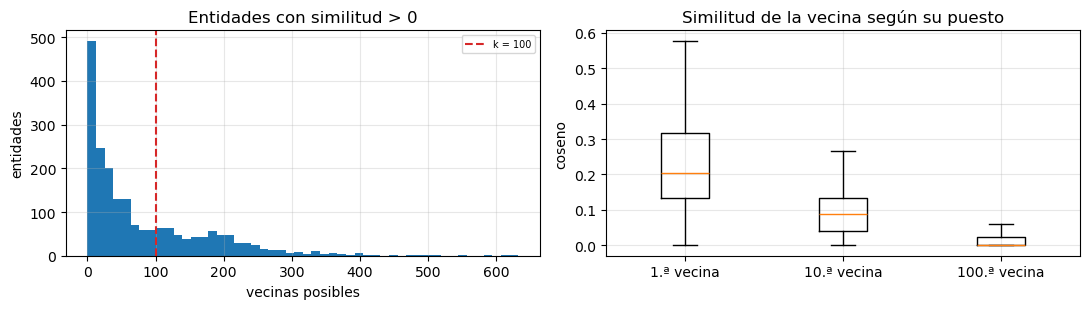

,vecinas_mediana,pct_menos_de_100,sim_1_mediana,sim_10_mediana,sim_100_mediana
0,44,67.9,0.204,0.088,0.0


In [5]:
c = ctx[("val", "binaria")]
S_all = vecinas(c["X"], c["forma"][0]).toarray()[c["entidades"]]
n_vec = (S_all > 0).sum(1)
orden = -np.sort(-S_all, axis=1)
rangos = {1: orden[:, 0], 10: orden[:, 9], 100: orden[:, 99]}
fig, ax = plt.subplots(1, 2, figsize=(11, 3.2))
ax[0].hist(n_vec, bins=50); ax[0].axvline(100, color="tab:red", ls="--", label="k = 100")
ax[0].set_title("Entidades con similitud > 0"); ax[0].set_xlabel("vecinas posibles"); ax[0].set_ylabel("entidades"); ax[0].legend(fontsize=7)
ax[1].boxplot(list(rangos.values()), labels=[f"{r}.ª vecina" for r in rangos], showfliers=False)
ax[1].set_title("Similitud de la vecina según su puesto"); ax[1].set_ylabel("coseno")
mostrar_fig("similitud_entidades")
similitud = pd.DataFrame([{"vecinas_mediana": int(np.median(n_vec)), "pct_menos_de_100": round(100 * (n_vec < 100).mean(), 1),
                           **{f"sim_{r}_mediana": round(float(np.median(v)), 3) for r, v in rangos.items()}}])
similitud

- Mediana tiene solo **44 entidades con al menos un proveedor en común**; el **67.9%** tiene menos de 100

- La similitud cae rápido: mediana de 0.20 con el 1er vecino, 0.09 con el 10mo y **0 con la 100mo**

- Con `k = 100`, la mayoría de las entidades usa a **todas** sus vecinas reales

- Las grandes (EsSalud, gobiernos regionales) se quedan con las 100 más parecidas

- Por eso el NDCG casi no cambia desde 50: las vecinas que se agregan pesan casi 0

In [6]:
grilla_u = []
for s in RANGO_SENAL:
    c = ctx[("val", s)]
    for k in RANGO_K_VEC:
        t0 = time.time()
        recs = top_k(puntaje_usuario(c["X"], k), c["entidades"], c["vistos"], c["catalogo"], k=K_EVAL)
        grilla_u.append({"senal": s, "k": k, **evaluar(recs, c["pos"], c["catalogo"].sum()), "seg": round(time.time() - t0, 1)})
grilla_u = pd.DataFrame(grilla_u)
grilla_u.pivot(index="k", columns="senal", values="ndcg@10")

senal,binaria,log_monto,n_adj
k,,,
10,0.0766,0.0766,0.0778
20,0.0941,0.0920,0.0927
50,0.1060,0.1049,0.1037
100,0.1066,0.1040,0.1030
200,0.1050,0.1022,0.1014
400,0.1047,0.1021,0.1017


- El NDCG sube hasta 50-100 vecinos (0.077 con 10 → **0.107 con 100**) y luego baja levemente

- Las tres señales quedan a menos de 0.003 entre sí

- La binaria es la mejor en casi todos los k

---
### **2. Item-item**

- Coseno entre las columnas: dos proveedores se parecen si les adjudican las mismas entidades

- Cada proveedor candidato conserva sus `k` proveedores más parecidos

- Puntaje(e, p) = Σ similitud(p, j) · señal(e, j) sobre los proveedores j de e que están entre los vecinos de p

In [7]:
def puntaje_item(X, k, catalogo, bloque=2000):
    cols = np.flatnonzero(catalogo)
    Xc = X[:, cols].tocsc()
    Xc = sp.csc_matrix(Xc.multiply(1 / np.sqrt(np.asarray(Xc.multiply(Xc).sum(0))).clip(1e-9)))
    partes = []
    for i in range(0, len(cols), bloque):
        S = (Xc.T @ Xc[:, i:i + bloque]).toarray()
        S[np.arange(i, min(i + bloque, len(cols))), np.arange(S.shape[1])] = 0
        if k < S.shape[0]:
            np.put_along_axis(S, np.argpartition(-S, k, axis=0)[k:], 0, axis=0)
        partes.append(sp.csc_matrix(S))
    Sk = sp.hstack(partes).tocsr()
    Xh = X[:, cols].tocsr()

    def f(idx):
        out = np.zeros((len(idx), X.shape[1]), dtype=np.float32)
        out[:, cols] = (Xh[idx] @ Sk).toarray()
        return out
    return f

grilla_i = []
for s in RANGO_SENAL:
    c = ctx[("val", s)]
    for k in RANGO_K_VEC:
        t0 = time.time()
        recs = top_k(puntaje_item(c["X"], k, c["catalogo"]), c["entidades"], c["vistos"], c["catalogo"], k=K_EVAL)
        grilla_i.append({"senal": s, "k": k, **evaluar(recs, c["pos"], c["catalogo"].sum()), "seg": round(time.time() - t0, 1)})
grilla_i = pd.DataFrame(grilla_i)
grilla_i.pivot(index="k", columns="senal", values="ndcg@10")

senal,binaria,log_monto,n_adj
k,,,
10,0.0457,0.0487,0.0445
20,0.0501,0.0494,0.0479
50,0.0508,0.0496,0.0500
100,0.0489,0.0498,0.0507
200,0.0521,0.0520,0.0521
400,0.0529,0.0520,0.0517


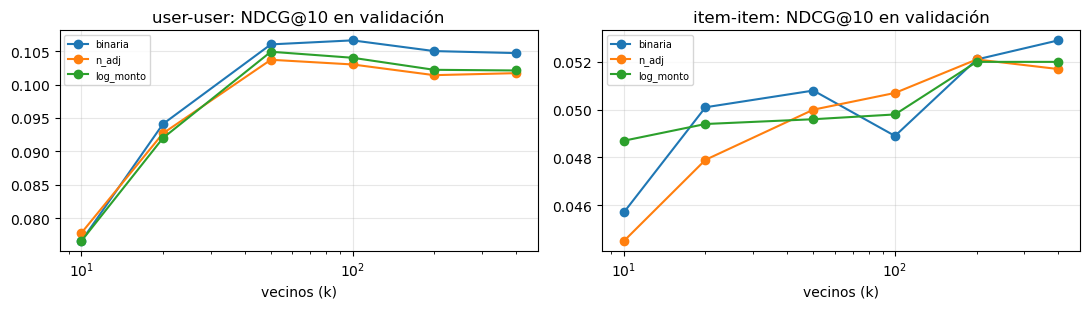

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.2))
for i, (nombre, g) in enumerate({"user-user": grilla_u, "item-item": grilla_i}.items()):
    for s in RANGO_SENAL:
        d = g[g.senal == s]
        ax[i].plot(d.k, d["ndcg@10"], "o-", label=s)
    ax[i].set_xscale("log"); ax[i].set_title(f"{nombre}: NDCG@10 en validación"); ax[i].set_xlabel("vecinos (k)"); ax[i].legend(fontsize=7)
mostrar_fig("grilla_vecindario")

- Item-item queda muy por debajo (máximo **0.053** con 400 vecinos)

- Con proveedores de grado bajo, la similitud entre columnas se apoya en muy pocas entidades y es ruidosa

#### a. Grado de los proveedores

Cuántas entidades tiene cada proveedor del catálogo: es la información con la que item-item calcula sus similitudes

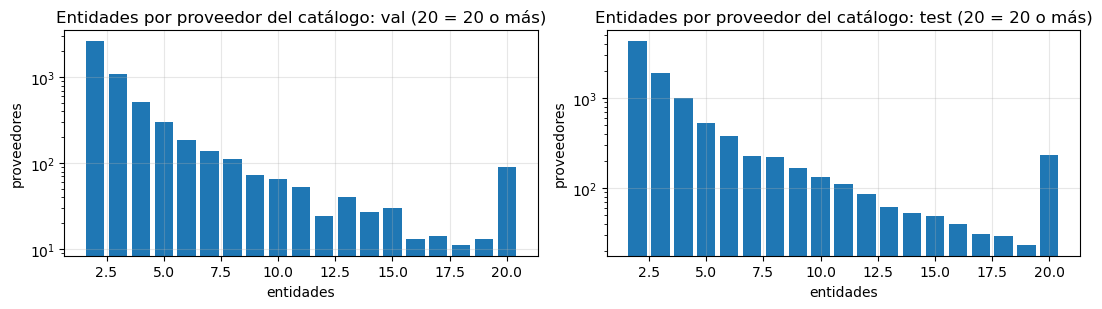

,particion,catalogo,pct_grado_2,grado_mediano
0,val,5474,49.0,3.0
1,test,9653,45.4,3.0


In [9]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.2))
for i, p in enumerate(PARTICIONES):
    c = ctx[(p, "binaria")]
    g = np.asarray(c["vistos"].sum(0)).ravel()[c["catalogo"]]
    v = pd.Series(np.minimum(g, 20)).value_counts().sort_index()
    ax[i].bar(v.index, v.values); ax[i].set_yscale("log")
    ax[i].set_title(f"Entidades por proveedor del catálogo: {p} (20 = 20 o más)"); ax[i].set_xlabel("entidades"); ax[i].set_ylabel("proveedores")
mostrar_fig("grado_proveedores")
grado_cat = pd.DataFrame([{"particion": p, "catalogo": int(ctx[(p, "binaria")]["catalogo"].sum()),
                           "pct_grado_2": round(100 * (np.asarray(ctx[(p, "binaria")]["vistos"].sum(0)).ravel()[ctx[(p, "binaria")]["catalogo"]] == 2).mean(), 1),
                           "grado_mediano": float(np.median(np.asarray(ctx[(p, "binaria")]["vistos"].sum(0)).ravel()[ctx[(p, "binaria")]["catalogo"]]))}
                          for p in PARTICIONES])
grado_cat

- El **45-49% del catálogo tiene exactamente 2 entidades** y el grado mediano es 3

- Item-item compara proveedores por sus entidades en común

- Con 2-3 entidades por proveedor, la similitud se apoya en uno o dos casos y es poco confiable

- User-user, en cambio, compara entidades que tienen decenas de proveedores: tiene mucha más información por vector

---
### **3. Señal y vecinos elegidos**

In [10]:
mejor = {n: g.loc[g["ndcg@10"].idxmax()] for n, g in {"usuario": grilla_u, "item": grilla_i}.items()}
pd.DataFrame(mejor).T

,senal,k,precision@10,recall@10,ndcg@10,hit@10,cobertura,seg
usuario,binaria,100,0.0587,0.1101,0.1066,0.3875,0.392,2.5
item,binaria,400,0.0311,0.0586,0.0529,0.2135,0.787,3.4


- **User-user:** señal binaria y `k = 100` (NDCG 0.107 en validación)

- **Item-item:** señal binaria y `k = 400` (NDCG 0.053)

- `SENAL = binaria`: la intensidad no aporta, porque el 81% de los pares tiene una sola adjudicación

In [11]:
cfg["senal"] = SENAL
cfg["k_vec"] = K_VEC
guardar_config(cfg)

---
### **4. Evaluación en test**

- Con los parámetros elegidos se recalculan las similitudes en cada partición: 2023 → 2024 y 2023-2024 → 2025

- Por entidad se guardan los **100 proveedores con mayor puntaje** (`N_CAND`), en validación y en test

In [12]:
modelos = {"usuario": lambda c: puntaje_usuario(c["X"], K_VEC["usuario"]),
           "item": lambda c: puntaje_item(c["X"], K_VEC["item"], c["catalogo"])}
evaluacion = []
for p in PARTICIONES:
    c = ctx[(p, SENAL)]
    for nombre, f in modelos.items():
        t0 = time.time()
        recs = top_k(f(c), c["entidades"], c["vistos"], c["catalogo"])
        guardar_recs(recs, f"{nombre}_{p}")
        evaluacion.append({"particion": p, "modelo": nombre, **evaluar(recs, c["pos"], c["catalogo"].sum()), "seg": round(time.time() - t0, 1)})
evaluacion = pd.DataFrame(evaluacion)
evaluacion

,particion,modelo,precision@10,recall@10,ndcg@10,hit@10,cobertura,seg
0,val,usuario,0.0588,0.1107,0.1066,0.3885,0.3946,3.4
1,val,item,0.0315,0.0600,0.0541,0.2165,0.7896,4.8
2,test,usuario,0.0439,0.1037,0.0946,0.3305,0.2219,3.0
3,test,item,0.0265,0.0595,0.0525,0.2079,0.5984,6.5


- **User-user en test: NDCG@10 = 0.095**, recall@10 = 0.104

- Item-item: 0.053 en test

- Ambos calculan las recomendaciones de 2,112 entidades en 3-7 s

#### a. Frente a las líneas base

User-user e item-item contra la popularidad global y regional

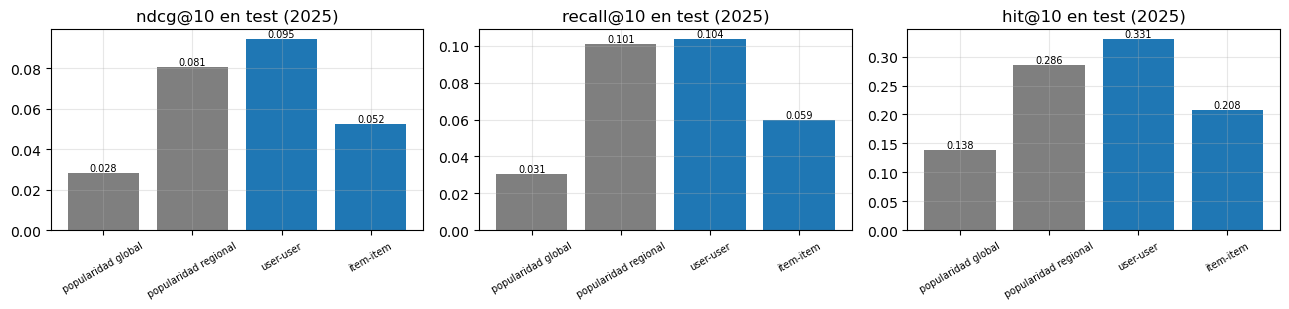

,modelo,precision@10,recall@10,ndcg@10,hit@10,cobertura
0,popularidad global,0.0157,0.0307,0.0281,0.1378,0.0019
1,popularidad regional,0.0358,0.1008,0.0807,0.2860,0.0400
2,user-user,0.0439,0.1037,0.0946,0.3305,0.2219
3,item-item,0.0265,0.0595,0.0525,0.2079,0.5984


In [13]:
c = ctx[("test", SENAL)]
NOMBRES = {"popularidad": "popularidad global", "regional": "popularidad regional", "usuario": "user-user", "item": "item-item"}
comp = pd.DataFrame([{"modelo": n, **evaluar(leer_recs(f"{m}_test"), c["pos"], c["catalogo"].sum())} for m, n in NOMBRES.items()])
fig, ax = plt.subplots(1, 3, figsize=(13, 3.2))
for i, met in enumerate(["ndcg@10", "recall@10", "hit@10"]):
    ax[i].bar(comp.modelo, comp[met], color=["tab:gray", "tab:gray", "tab:blue", "tab:blue"])
    for j, v in enumerate(comp[met]):
        ax[i].text(j, v, f"{v:.3f}", ha="center", va="bottom", fontsize=7)
    ax[i].set_title(f"{met} en test (2025)"); ax[i].tick_params(axis="x", rotation=30, labelsize=7)
mostrar_fig("vecindario_vs_base")
comp

- **User-user supera a ambas líneas base** en NDCG (0.095 vs 0.081 regional) y en hit (0.33 vs 0.29)

- Su recall (0.104) es casi igual al de la regional (0.101): la ganancia está en **ordenar mejor**

- **Item-item queda bajo la regional** en todas las métricas, pero recomienda 15× más variedad (cobertura 0.60 vs 0.04)

#### b. Por actividad de la entidad

NDCG@10 en test según cuántos proveedores distintos tuvo la entidad en 2023-2024

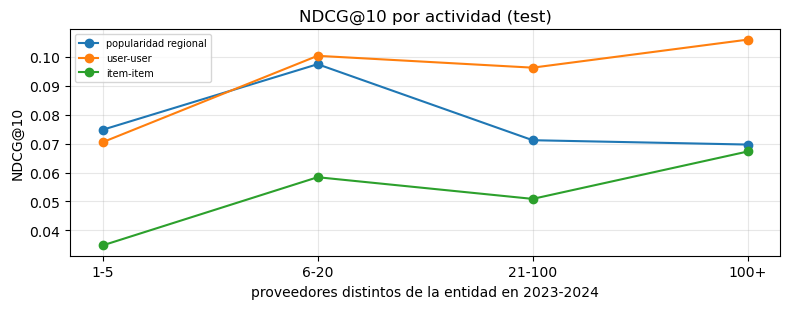

,item-item,popularidad regional,user-user,entidades
1-5,0.0348,0.0748,0.0705,331
6-20,0.0584,0.0975,0.1004,727
21-100,0.0509,0.0712,0.0963,858
100+,0.0673,0.0697,0.1060,196


In [14]:
grado_e = np.asarray(c["vistos"].sum(1)).ravel()
tramo = pd.cut(pd.Series(grado_e[c["entidades"]], index=c["entidades"]), [0, 5, 20, 100, float("inf")], labels=["1-5", "6-20", "21-100", "100+"])
por_tramo = []
for t in tramo.cat.categories:
    pos_t = {e: c["pos"][e] for e in tramo.index[tramo == t]}
    for m in ["regional", "usuario", "item"]:
        r = leer_recs(f"{m}_test")
        por_tramo.append({"tramo": t, "entidades": len(pos_t), "modelo": NOMBRES[m],
                          "ndcg@10": evaluar(r[r.entidad_idx.isin(pos_t)], pos_t, c["catalogo"].sum())["ndcg@10"]})
por_tramo = pd.DataFrame(por_tramo)
fig, ax = plt.subplots(figsize=(8, 3.2))
for m in por_tramo.modelo.unique():
    d_ = por_tramo[por_tramo.modelo == m]
    ax.plot(d_.tramo.astype(str), d_["ndcg@10"], "o-", label=m)
ax.set_xlabel("proveedores distintos de la entidad en 2023-2024"); ax.set_ylabel("NDCG@10"); ax.set_title("NDCG@10 por actividad (test)")
ax.legend(fontsize=7)
mostrar_fig("vecindario_por_tramo")
por_tramo.pivot(index="tramo", columns="modelo", values="ndcg@10").join(por_tramo.groupby("tramo").entidades.first()).reindex(tramo.cat.categories)

- **Entidades con 1-5 proveedores (331):** la regional (0.075) supera levemente al user-user (0.071)

- **Desde 6 proveedores**, el user-user gana, y la ventaja crece con la actividad (0.106 vs 0.070 en 100+)

- Item-item queda último en todos los tramos

---
### **5. Ejemplo: entidades vecinas**

Las vecinas de una entidad grande, para ver qué "parecido" captura el user-user

In [15]:
ent = pd.read_parquet(datos_dir / "entidades")
c = ctx[("test", SENAL)]
S = vecinas(c["X"], K_VEC["usuario"])
e0 = int(np.asarray(c["vistos"].sum(1)).ravel().argmax())
fila = S[e0].toarray().ravel()
top = np.argsort(-fila)[:8]
vecinas_ej = ent.loc[top, ["entidad_key", "nombre", "region"]].assign(similitud=fila[top].round(3))
print("entidad:", ent.nombre[e0], "|", ent.region[e0])
vecinas_ej

entidad: SEGURO SOCIAL DE SALUD | LIMA


,entidad_key,nombre,region,similitud
71,ENT:200551,INSTITUTO NACIONAL DE SALUD DEL NIÑO - SAN BORJA,LIMA,0.201
109,ENT:203086,HOSPITAL DE EMERGENCIAS VILLA EL SALVADOR,LIMA,0.197
31,ENT:200038,DIRECCIÓN DE SANIDAD DE LA PNP,LIMA,0.192
23,ENT:200363,CENTRO NACIONAL DE ABASTECIMIENTO DE RECURSOS ESTRATEGICOS EN SALUD,LIMA,0.182
93,ENT:10215,HOSPITAL NACIONAL DOS DE MAYO,LIMA,0.178
67,ENT:10198,INSTITUTO NACIONAL DE SALUD DEL NIÑO,LIMA,0.177
51,ENT:10194,INSTITUTO NACIONAL DE ENFERMEDADES NEOPLASICAS,LIMA,0.170
197,ENT:10424,GOBIERNO REGIONAL DE AREQUIPA-HOSPITAL REGIONAL HONORIO DELGADO,AREQUIPA,0.163


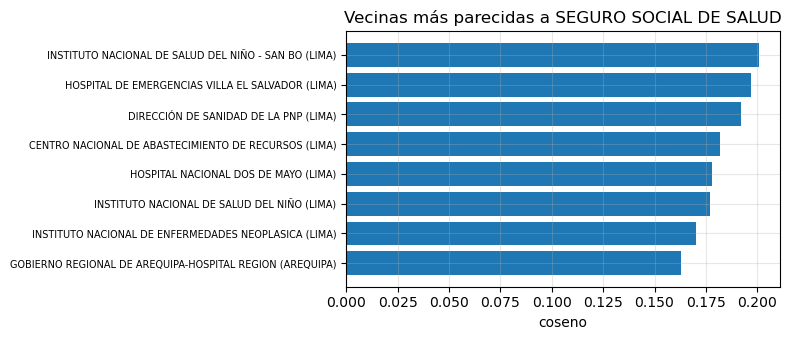

In [16]:
fig, ax = plt.subplots(figsize=(8, 3.5))
v = vecinas_ej.iloc[::-1]
ax.barh(v.nombre.str[:45] + " (" + v.region + ")", v.similitud)
ax.set_xlabel("coseno"); ax.set_title(f"Vecinas más parecidas a {ent.nombre[e0]}")
ax.tick_params(axis="y", labelsize=7)
mostrar_fig("vecinas_ejemplo")

- Las vecinas de EsSalud son **hospitales e institutos de salud**, casi todos en Lima

- El user-user captura un "parecido" por **rubro y región**, sin haber visto el texto

#### a. Verificación

In [17]:
for p in PARTICIONES:
    c = ctx[(p, SENAL)]
    for m in modelos:
        r = leer_recs(f"{m}_{p}")
        assert set(r.entidad_idx) == set(c["pos"]) and c["catalogo"][r.proveedor_idx].all(), (m, p)
        assert c["vistos"][r.entidad_idx.to_numpy(), r.proveedor_idx.to_numpy()].sum() == 0, (m, p)
    print(f"{p}: recomendaciones dentro del catálogo y sin pares vistos | OK")

val: recomendaciones dentro del catálogo y sin pares vistos | OK
test: recomendaciones dentro del catálogo y sin pares vistos | OK


---
### **6. Escritura de resultados**

In [18]:
escritos = guardar_tablas({"grilla_usuario": grilla_u, "grilla_item": grilla_i, "evaluacion_vecindario": evaluacion,
                           "vecinas_ejemplo": vecinas_ej, "similitud_entidades": similitud, "grado_catalogo": grado_cat,
                           "vecindario_vs_base": comp, "vecindario_por_tramo": por_tramo})

Escrito en 03_Recomend/temp/b_vecindario/: grilla_usuario, grilla_item, evaluacion_vecindario, vecinas_ejemplo, similitud_entidades, grado_catalogo, vecindario_vs_base, vecindario_por_tramo


#### a. Verificación

In [19]:
verificar_salidas(escritos)

OK: 8 tablas (parquet + json) | 6 figuras: grado_proveedores, grilla_vecindario, similitud_entidades, vecinas_ejemplo, vecindario_por_tramo, vecindario_vs_base


---
### **7. Cerrar sesión**

In [20]:
spark.stop()